# Robustness and operational scenarios: what happens when the plan meets reality?

**How fragile are optimised plans when execution runs late and the plan is not redone? And what changes, in the solver, with lower capacity, a limited fleet (with priority customers) and flexible windows, and how stable is reoptimisation when some customers enter or leave?** This notebook reads results that were already produced and frozen (`outputs/frozen/phase_c/`); no solver is run here.

**Pre-registered protocol (Nosek et al., 2018)** (`reports/protocolo-fase-c.md`, registered and clarified before the run; results in `reports/fase-c-robustez.md`). The phase answers findings 1 and 2 of the external audit (`reports/plano-sanidade-auditoria.md`): layer B had no customer dropping, priority, fleet limit or lateness, and the fragility of the plans had not been measured. There are four blocks:

- **C1, robustness of the fixed plan (no solver; Gendreau et al., 1996):** the frozen evaluation plans (OR-Tools [Perron & Furnon, 2026] at the median replicate and the two baselines, 42 instances) are executed without replanning under travel-time shocks (× (1 + ε), ε ~ U(0, a), with a = 5%, 10% and 20%), service-time shocks (up to +20%) and the combination (travel up to +10% and service up to +20%), with 1 000 Monte Carlo draws (Metropolis & Ulam, 1949) per plan and scenario and a fixed seed; an arrival after the end of the window is recorded as **lateness**, and service happens anyway. Here the evaluation instances are used **only descriptively** (nothing is adjusted).
- **C2, solver scenarios (only the 14 development instances):** C2.1 reduced capacity (100%, 90% and 80% of Q); C2.2 limited fleet with penalised dropping (Archetti et al., 2014) and **priority** (K equal to the reference fleet minus 1 and minus 2; 20% of the customers are priority, with a penalty 10 times larger); C2.3 flexible windows, with penalised lateness (Taillard et al., 1997).
- **C3, stability of reoptimisation (development only; Pillac et al., 2013):** remove or insert 10% of the customers and reoptimise, with a warm start (from the previous plan) or a cold start, against a noise floor.

**Layer B: no comparison with SINTEF anywhere.** Each scenario is compared with the **reference plan of the same instance** (the v2 solver, scale 10 000, 30 s and 3 replicates, on the unchanged instance; lexicographic representative replicate, defined in this project, the 2nd of 3). In C2.2 and C2.3, the representative replicate is chosen by dedicated criteria (fewest priority and dropped customers in C2.2; fewest late customers and smallest total lateness in C2.3), fixed before the run because the general rule (vehicles, distance) would favour a plan that drops or delays more. All results are descriptive; the solver objective is still fleet and then distance, and neither robustness nor time is optimised.

## 1. Environment setup

In this section the instance split, the effective configuration (`config/experiment.toml`) and the frozen results of each block are loaded; the loaders reject instances of the wrong set (C1 accepts only evaluation instances; C2 and C3, only development ones). The first table shows the effective configuration of the phase; the second audits C1 (plans stressed, scenarios and draws per method); the third audits the solver blocks (cells, instances, feasibility under the double-precision verifier and mean runtime).

In [1]:
LANG = "en"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import (
    benchmark,
    config,
    eda,
    paths,
    phase_c_view,
    results,
    viz_robustness,
)
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
cfg = config.load_config()
robustness = results.load_robustness(R["phase_c_C1"], split)
capacity = results.load_phase_c_cells(R["phase_c_capacity"], split)
fleet = results.load_phase_c_cells(R["phase_c_fleet_priority"], split)
soft = results.load_phase_c_cells(R["phase_c_soft_windows"], split)
removal = results.load_phase_c_cells(R["phase_c_removal"], split)
insertion = results.load_phase_c_cells(R["phase_c_insertion"], split)
reference = phase_c_view.reference_plans(capacity)
blocks = {
    "capacity": capacity,
    "fleet_priority": fleet,
    "soft_windows": soft,
    "removal": removal,
    "insertion": insertion,
}

display(eda.localize_columns(phase_c_view.config_table(cfg, LANG), LANG))
display(eda.localize_columns(phase_c_view.robustness_integrity(robustness["cells"], LANG), LANG))
display(eda.localize_columns(phase_c_view.block_overview(blocks, LANG), LANG))

,Indicator,Value
0,Solver (fleet strategy + first solution + meta...,fixed_cost + SAVINGS + GUIDED_LOCAL_SEARCH
1,Integer scale and relative fixed cost,"10000, k = 10"
2,Budget per run (s) · replicates · processes,30 · 3 · 8
3,Seed of the draws,20261118
4,C1: draws · travel shock · service shock · com...,"1000 · 5%, 10%, 20% · 20% · 10%"
5,C2.1: capacity (fraction of Q),"100%, 90%, 80%"
6,C2.2: limited fleet · priority share · priorit...,"K − 1, K − 2 · 20% · 10×"
7,C2.3: limited fleet · lateness cost (× distanc...,"K − 1 · 1×, 10×"
8,C3: share of customers removed or inserted,10%


,Method,No. of instances,Plans stressed,Shock scenarios,Draws per plan and scenario
0,OR-Tools,42,42,5,1000
1,Nearest neighbour with time windows,42,42,5,1000
2,Deadline-first greedy,42,42,5,1000


,Block,Cells,No. of instances,Feasible,Mean runtime (s)
0,C2.1 · reduced capacity,126,14,126,30.0
1,C2.2 · limited fleet with priority,168,14,168,30.0
2,C2.3 · soft windows,84,14,18,7.0
3,C3 · removal of 10%,84,14,84,30.0
4,C3 · insertion of 10%,98,14,98,30.0


**Insight.** The effective configuration matches the protocol: solver `fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH` with scale 10 000 and relative fixed cost k = 10, 30 s per run, 3 replicates and 8 processes, seed 20261118; C1 with 1 000 draws, travel shocks of 5%, 10% and 20%, service of 20% and combined 10% and 20%; C2.1 with 100%, 90% and 80% of the capacity; C2.2 with K − 1 and K − 2, 20% priority customers and penalty 10×; C2.3 with K − 1 and lateness at 1× and 10× the distance cost; C3 with 10% of the customers. In C1, the three methods have 42 plans stressed (42 evaluation instances), 5 shock scenarios and 1 000 draws per plan and scenario. The solver blocks have 126 cells (C2.1: 14 instances × 3 capacities × 3 replicates), 168 (C2.2: 14 × 2 fleets × 2 variants × 3), 84 (C2.3: 14 × 2 costs × 3), 84 (removal) and 98 (insertion: 84 reoptimisations plus 14 base plans with 90% of the customers), all from 14 development instances. All cells are feasible, **except** those of C2.3: only 18 of the 84 are feasible (this is why section 5 is of little information). The mean runtime is 30.0 s in the blocks that use the whole budget and 7.0 s in C2.3, because many runs fail almost at once. **Limitations:** feasibility here is against the transformed instance of each scenario (reduced capacity, customers removed), not against the original instance; the representative replicates of C2.2 and C2.3 follow dedicated criteria, not the general rule. **Next decision:** read the robustness of the fixed plans first (C1).

## 2. C1 — Robustness of the fixed plan under delays

**Question:** when travel or service takes longer than planned (Gendreau et al., 1996) and the plan is not redone, what share of the customers is served after the end of the window, and is the OR-Tools plan more fragile than the baseline plans? **What is shown:** per shock scenario and method, means over the 42 plans of: customers served late (%), returns to the depot after the horizon (%), routes with at least one late customer (%), and the mean and P95 lateness among the late customers (in the instance's time units); and a plot with the late customers by scenario (a) and the late rate by nominal slack bin in the travel +0–10% scenario (b). Shocks are independent per arc and customer, with common random numbers across scenarios for each instance and method.

,Scenario,Method,Plans,Customers served late (%),Late return to the depot (%),Routes with ≥ 1 late customer (%),Mean lateness among late customers,P95 lateness among late customers
0,Travel +0–5%,OR-Tools,42,4.6,9.6,55.6,1.7,3.0
1,Travel +0–5%,Nearest neighbour with time windows,42,5.6,19.5,44.2,2.9,6.0
2,Travel +0–5%,Deadline-first greedy,42,13.4,32.2,56.6,3.5,7.6
3,Travel +0–10%,OR-Tools,42,6.3,13.4,63.8,3.9,6.9
4,Travel +0–10%,Nearest neighbour with time windows,42,9.3,32.9,53.5,5.5,12.0
5,Travel +0–10%,Deadline-first greedy,42,21.1,43.3,66.9,7.4,15.9
6,Travel +0–20%,OR-Tools,42,9.3,18.4,70.2,8.1,14.9
7,Travel +0–20%,Nearest neighbour with time windows,42,16.0,45.7,63.8,11.8,25.3
8,Travel +0–20%,Deadline-first greedy,42,31.7,55.7,77.3,16.0,34.6
9,Service +0–20%,OR-Tools,42,16.6,22.9,84.2,23.9,56.3


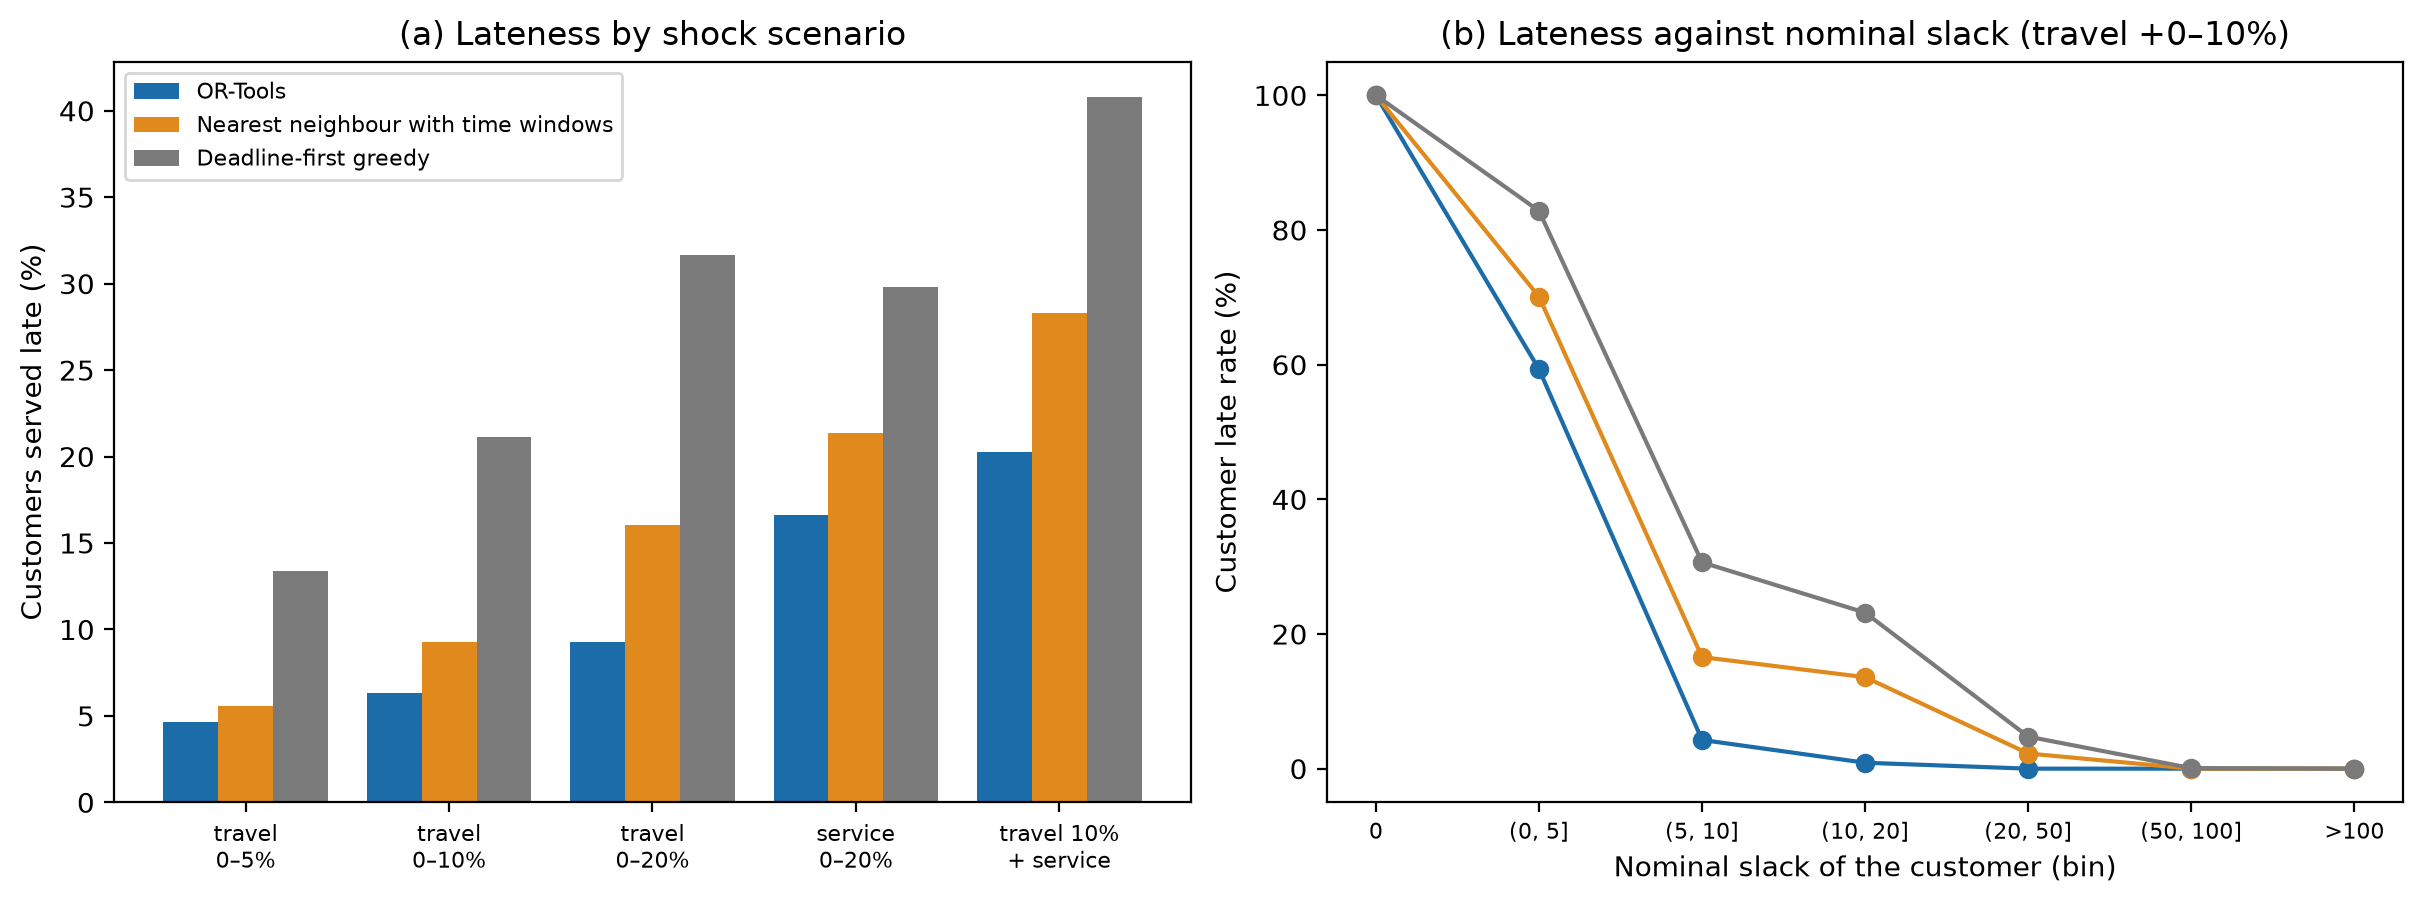

In [2]:
display(eda.localize_columns(phase_c_view.robustness_table(robustness["summary"], "overall", LANG), LANG))

viz_robustness.plot_robustness(robustness["summary"], robustness["slack_lateness"], LANG)
plt.show()

**Insight.** The optimised plan is **not more fragile than the baselines per customer**: with travel +0–10%, 6.3% of the OR-Tools customers are served late, against 9.3% (nearest neighbour) and 21.1% (greedy); in all five scenarios OR-Tools has the smallest share (from 4.6% with travel +0–5% to 20.3% with travel and service, against 5.6% to 28.3% and 13.4% to 40.8%). The late return to the depot is about 2 to 3 times smaller for OR-Tools in the travel scenarios (for example, 13.4% against 32.9% and 43.3% with +0–10%) and 22.9% against 51.3% and 53.3% with service +0–20%. Per **route**, however, the picture is different: OR-Tools has more routes with some lateness than the nearest neighbour in every scenario (55.6% against 44.2% with travel +0–5%; 84.2% against 71.1% with service) and more than the greedy under the service shock (84.2% against 72.5%; 89.9% against 84.3% in the combined one), although fewer than the greedy in the travel scenarios (63.8% against 66.9% with +0–10%). This is consistent with OR-Tools using fewer vehicles, with longer routes and more customers, so a single accumulated delay is enough to mark the route, but that explanation was not tested. The lateness is never negligible: even with travel +0–5%, more than half of the OR-Tools routes (55.6%) and of the greedy routes (56.6%) have some late customer. Among the late customers, the mean lateness of OR-Tools grows from 1.7 (travel +0–5%) to 23.9 (service +0–20%) and 26.7 (combined). **Limitations:** these are 42 evaluation instances used descriptively, with one plan per instance and method; the shocks are independent across arcs, without the spatial and temporal correlation of real traffic; the values are means over plans of instances of very different scales; the solver does not optimise robustness. **Next decision:** see what explains the fragility, the nominal slack.

**Question:** is the fragility of a customer explained by the slack the nominal plan gives it (the difference between the end of the window and the start of service)? **What is shown:** the Spearman rank correlation (Spearman, 1904), per scenario and method, between each customer's nominal slack and its late rate across the draws (expected: negative), and the late rate (in %) by nominal-slack bin in the travel +0–10% scenario, with the number of customers in each bin in the OR-Tools plans. Slack 0 means that nominal service already starts at the end of the window.

In [3]:
display(eda.localize_columns(phase_c_view.slack_correlation_table(robustness["slack_correlation"], LANG), LANG))
display(eda.localize_columns(phase_c_view.slack_bins_table(robustness["slack_lateness"], "travel_0.10", LANG), LANG))

,Scenario,OR-Tools,Nearest neighbour with time windows,Deadline-first greedy
0,Travel +0–5%,-0.41,-0.45,-0.63
1,Travel +0–10%,-0.48,-0.54,-0.71
2,Travel +0–20%,-0.57,-0.63,-0.78
3,Service +0–20%,-0.37,-0.42,-0.54
4,Travel +0–10% and service +0–20%,-0.47,-0.54,-0.67


,Nominal slack (bin),No. of customers,OR-Tools,Nearest neighbour with time windows,Deadline-first greedy
0,0,114,100.0,100.0,100.0
1,"(0, 5]",231,59.3,70.1,82.8
2,"(5, 10]",305,4.3,16.6,30.6
3,"(10, 20]",245,0.9,13.6,23.2
4,"(20, 50]",716,0.0,2.3,4.8
5,"(50, 100]",878,0.0,0.0,0.1
6,>100,1711,0.0,0.0,0.0


**Insight.** The correlation between slack and late rate is **negative in all 15 cases** (5 scenarios × 3 methods): from −0.37 (OR-Tools, service +0–20%) to −0.78 (greedy, travel +0–20%); for OR-Tools it ranges from −0.37 to −0.57, for the nearest neighbour from −0.42 to −0.63 and for the greedy from −0.54 to −0.78. The more slack, the less lateness, and the effect is strong in the low bins: with travel +0–10%, the 114 OR-Tools customers with no slack are late in 100% of the draws, the 231 with slack up to 5 in 59.3%, the 305 between 5 and 10 in 4.3% and the 245 between 10 and 20 in 0.9%; above 20 of slack OR-Tools is never late (716, 878 and 1 711 customers in the last three bins). In the same bins, the baselines are late more often: up to 5 of slack, 70.1% (nearest neighbour) and 82.8% (greedy); between 5 and 10, 16.6% and 30.6%; between 10 and 20, 13.6% and 23.2%. That is, the lower per-customer fragility of OR-Tools in the previous section does not come only from having more slack: within the same nominal-slack bin it is also late less often, but the cause of that (for example, the position of the customer in the route) was not investigated. **Limitations:** the correlation is between ranks and does not indicate causality; the slack bins mix customers from instances of very different scales (slack in the instance's time units); the slack-0 bin gathers customers whose nominal service already starts at the end of the window, so any positive delay makes them late. **Next decision:** see how the fragility varies by family.

**Question:** does the fragility depend on the instance type? **What the table shows:** per family and in the travel +0–10% scenario, the number of plans, the mean nominal slack of the OR-Tools plans and the percentage of customers served late under each method.

In [4]:
display(eda.localize_columns(phase_c_view.robustness_by_family(robustness["summary"], "travel_0.10", LANG), LANG))

,Family,Plans,Mean nominal slack (OR-Tools),OR-Tools,Nearest neighbour with time windows,Deadline-first greedy
0,C1,7,168.1,1.0,2.5,10.8
1,C2,6,438.7,1.2,2.0,9.5
2,R1,9,37.6,13.1,14.4,24.2
3,R2,8,237.9,4.9,11.7,26.1
4,RC1,6,41.1,11.1,8.7,21.7
5,RC2,6,193.0,4.7,14.1,32.9


**Insight.** For OR-Tools, with travel +0–10%, the share of late customers is 13.1% in R1 and 11.1% in RC1 (mean nominal slack of 37.6 and 41.1), against 1.0% in C1 and 1.2% in C2 (slack of 168.1 and 438.7), 4.9% in R2 (237.9) and 4.7% in RC2 (193.0). The fragility follows the slack: the families with narrow windows and a short horizon (R1 and RC1) concentrate the lateness, and those with wide windows or clustered customers (C1, C2, R2, RC2) are almost never late. The order among the methods holds in most families (OR-Tools 1.0%, nearest neighbour 2.5% and greedy 10.8% in C1; 4.9%, 11.7% and 26.1% in R2), with one exception: in RC1, the nearest neighbour (8.7%) has fewer late customers than OR-Tools (11.1%). **Limitations:** there are 6 to 9 plans per family; the mean slack mixes different instance scales; the RC1 exception was not investigated. **Next decision:** move to the solver scenarios, starting with reduced capacity.

## 3. C2.1 — Reduced capacity

**Question:** if vehicle capacity falls to 90% and 80% of Q (for example, partly occupied or smaller vehicles), how many extra vehicles are needed and at what distance cost? **What is shown:** per capacity factor and **fleet class** against the reference plan of the same instance (equal or larger fleet), the number of instances, the extra vehicles (mean) and the distance change (mean and median, in %) **within the class only**, because the distance of plans with different fleets is not comparable; the "all" row gives the extra vehicles on average over the 14 instances and the infeasible cells; and the list of instances whose fleet grows. Hard model, re-solved at each capacity (3 replicates, 30 s).

In [5]:
display(eda.localize_columns(phase_c_view.capacity_by_level(capacity, reference, LANG), LANG))
display(eda.localize_columns(phase_c_view.capacity_instances(capacity, reference, LANG), LANG))

,Level,Fleet against the baseline plan,No. of instances,Infeasible cells,Extra vehicles (mean),"Distance change, mean (%)","Distance change, median (%)"
0,80%,all,14,0,0.57,NaN,NaN
1,80%,equal fleet,8,0,0.00,0.24,0.00
2,80%,larger fleet,6,0,1.33,13.56,10.72
3,90%,all,14,0,0.21,NaN,NaN
4,90%,equal fleet,11,0,0.00,-0.52,0.00
5,90%,larger fleet,3,0,1.00,13.86,14.73


,Instance,Level,Vehicles (reference plan),Vehicles (scenario),Extra vehicles,Distance change (%)
0,C103,90%,10,11,1,14.7
1,C106,90%,10,11,1,21.1
2,RC108,90%,11,12,1,5.8
3,C103,80%,10,12,2,20.4
4,C106,80%,10,12,2,33.6
5,C203,80%,3,4,1,12.3
6,C206,80%,3,4,1,9.1
7,R111,80%,11,12,1,-1.3
8,RC108,80%,11,12,1,7.2


**Insight.** With 90% of the capacity, 0.21 extra vehicle per instance is needed on average: 3 of the 14 instances (C103, C106 and RC108) use 1 more vehicle and 11 keep the fleet; with 80%, the mean is 0.57 and 6 instances have a larger fleet (1.33 extra vehicles on average: C103 and C106 with +2; C203, C206, R111 and RC108 with +1), while 8 keep the fleet. No cell is infeasible. Within the larger-fleet class, the distance grows by 13.9% on average (median 14.7%) with 90% and by 13.6% (median 10.7%) with 80%; with an equal fleet, the distance practically does not change (−0.52% on average with 90%, +0.24% with 80%, median 0.0% in both). Four of the six instances that grow with 80% are from the C families, in which capacity already determined the reference fleet (ratio 1.000 in notebook 02): where capacity is the limiting factor, any reduction turns into vehicles; elsewhere, the capacity slack absorbs the reduction. R111 shows a shorter distance (−1.3%) with one more vehicle, a value that is not comparable with the reference plan because the fleet is different. **Limitations:** only 14 development instances, with 3 to 8 per fleet class; a uniform capacity reduction is a stylised scenario; the distance within the larger-fleet class mixes instances of different scales. **Next decision:** limit the fleet, which forces some customers to be left unserved.

## 4. C2.2 — Limited fleet with penalised dropping and priority

**Question:** if the fleet is smaller than needed, how many customers go unserved, and does a larger penalty for priority customers protect them? **What is shown:** with K equal to the reference-plan fleet minus 1 and minus 2, any customer can be dropped at a penalty (Archetti et al., 2014), calibrated so that the solver drops only when the fleet forces it; 20% of the customers are priority (drawn per instance, fixed seed), with a penalty 10 times larger, and the priority variant is compared with the **same K with a uniform penalty**. The first table aggregates the 14 instances (customers and priority customers unserved, in total and in %, mean unserved demand and the distance change, which covers fewer customers and is **not comparable one to one**), with the paired difference per instance (priority minus uniform); the second lists, per instance, the customers and priority customers unserved under both variants; the plot summarises the two effects.

,Level,Variant,No. of instances,Customers not served,Priority customers not served,Priority customers not served (%),Common customers not served (%),Unserved demand (mean),"Distance change, mean (%)"
0,K − 1,With priority (10×),14,122.0,0.0,0.0,10.9,162.1,-0.4
1,K − 1,Uniform penalty,14,111.0,23.0,8.2,7.9,150.6,0.6
2,K − 2,With priority (10×),14,363.0,3.0,1.1,32.1,454.3,-14.0
3,K − 2,Uniform penalty,14,344.0,69.0,24.6,24.6,437.7,-20.7
4,K − 1,Difference (priority − uniform),14,0.8,-1.6,NaN,NaN,11.4,NaN
5,K − 2,Difference (priority − uniform),14,1.4,-4.7,NaN,NaN,16.6,NaN


,Instance,Level,Fleet limit K,Priority customers,Not served (uniform),Not served (with priority),Priority not served (uniform),Priority not served (with priority)
0,C103,K − 1,9,20,1,1,0,0
1,C103,K − 2,8,20,10,9,2,0
2,C106,K − 1,9,20,7,8,3,0
3,C106,K − 2,8,20,15,17,5,0
4,C203,K − 1,2,20,31,32,4,0
5,C203,K − 2,1,20,66,68,12,1
6,C206,K − 1,2,20,31,32,8,0
7,C206,K − 2,1,20,66,69,13,0
8,R108,K − 1,9,20,3,3,0,0
9,R108,K − 2,8,20,10,9,1,0


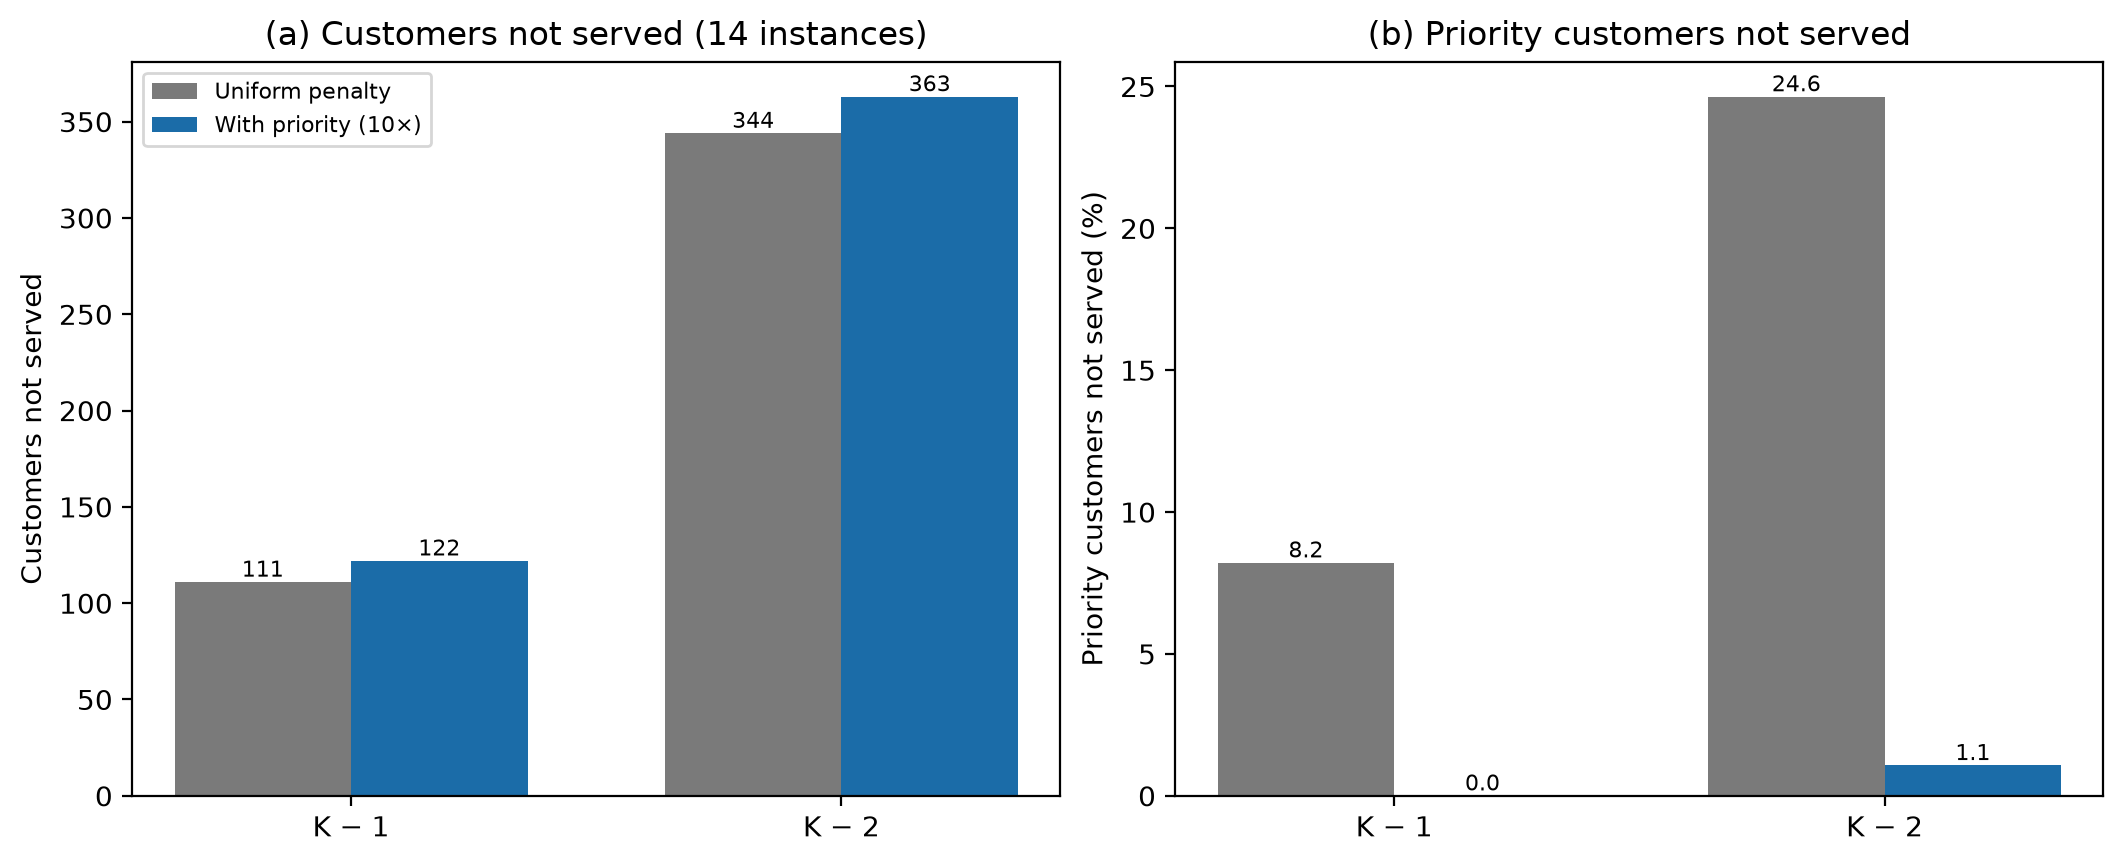

In [6]:
display(eda.localize_columns(phase_c_view.fleet_priority_by_level(fleet, reference, LANG), LANG))
display(eda.localize_columns(phase_c_view.fleet_priority_instances(fleet, reference, LANG), LANG))

viz_robustness.plot_fleet_priority(fleet, reference, LANG)
plt.show()

**Insight.** With one vehicle fewer (K − 1), the uniform penalty leaves 111 customers unserved over the 14 instances (about 8 per instance, 7.9% of the common customers), of which 23 are priority (8.2% of the priority customers); with priority, 122 customers go unserved and **0 priority customers**. With two vehicles fewer (K − 2), 344 customers (about 25 per instance), 69 of them priority (24.6%), against 363 customers and **3 priority customers** (1.1%) with priority. Priority therefore protects almost all priority customers (from 23 to 0 and from 69 to 3), at the cost of dropping slightly more common customers: +0.8 and +1.4 customers per instance, the share of common customers unserved goes from 7.9% to 10.9% (K − 1) and from 24.6% to 32.1% (K − 2), and the mean unserved demand rises by 11.4 and 16.6 units. The 3 priority customers that are still unserved with K − 2 are in instances with K = 1 (C203, R207 and RC206, 1 each), where the remaining fleet cannot hold all the priority customers; in series 2 with K = 1, the uniform penalty drops from 43 (R207) to 66 customers (C203 and C206). "Customers not served" stops being zero by construction and becomes an explicit business decision: priority is the lever. **Limitations:** only 14 instances, 20% priority customers drawn at random (unrelated to the customer's position), a single penalty ratio (10×); the distance of plans that serve different sets of customers is not comparable and is not interpreted; the model treats the drop penalty as a solver cost, not as a measured business value. **Next decision:** make the windows flexible instead of dropping customers.

**Caveat check: spread across replicates.** **Question:** is the number of customers dropped stable across the 3 replicates of the same cell? The penalty makes serving a customer cheaper than dropping it, but it does not guarantee that the heuristic drops the fewest customers possible. **What is shown:** the number of cell groups (instance × fleet limit × variant), how many have replicates that drop a different **number** of customers and how many drop different **sets**, and the groups where the replicates differ, with the number dropped by each replicate and the number of priority customers dropped (the tables above use the representative replicate).

In [7]:
display(eda.localize_columns(phase_c_view.dropped_spread_summary(fleet, LANG), LANG))
display(eda.localize_columns(phase_c_view.dropped_spread_table(fleet, LANG), LANG))


,Item,Count
0,Groups (instance × level × variant),56
1,Groups with a different number of customers no...,1
2,Groups with different sets of customers not se...,5


,Instance,Level,Variant,Replicates,Not served per replicate,Range,Priority not served per replicate,Distinct sets
0,RC108,K − 2,Uniform penalty,3,"9, 7, 7",2,"2, 1, 1",2
1,C106,K − 1,With priority (10×),3,"8, 8, 8",0,"0, 0, 0",2
2,R110,K − 2,With priority (10×),3,"4, 4, 4",0,"0, 0, 0",2
3,R110,K − 2,Uniform penalty,3,"5, 5, 5",0,"0, 2, 2",2
4,RC106,K − 2,Uniform penalty,3,"3, 3, 3",0,"1, 1, 1",2


**Insight.** The spread across replicates is small but real: of the 56 groups (14 instances × 2 fleet limits × 2 variants), 1 has replicates that drop a different number of customers and 5 drop different sets of customers. The clearest case is RC108 with K − 2 and uniform penalty, where the 3 replicates drop 9, 7 and 7 customers (priority customers dropped: 2, 1 and 1), a range of 2 customers; the other 4 groups (C106 with K − 1 and priority, R110 with K − 2 in both variants and RC106 with K − 2 uniform) drop the same number in every replicate (8, 4, 5 and 3) but not the same customers. **Caveat:** the drop penalty encourages service, but the heuristic does not guarantee a minimal set of dropped customers; the counts in the tables above are those of the representative replicate (in RC108 with K − 2 and uniform penalty, 7 customers, 1 of them priority), and another replicate of the same cell dropped 2 customers more. The averages of +0.8 and +1.4 common customers per instance attributed to priority are means over 14 instances and are smaller than the largest spread between replicates seen in a single instance (2 customers), so they are read as small, not as a precise cost. **Limitations:** 3 replicates per cell; the priority-versus-uniform comparison uses one representative replicate per group. **Next decision:** make the windows flexible instead of dropping customers.

## 5. C2.3 — Flexible windows with penalised lateness (little information)

**Exploratory block: only 3 of the 14 instances were solved (4 are infeasible by capacity and 7 failed in the initial construction). Its numbers are not a general result and must not be quoted without this caveat.**

**Question:** if the end of the windows can be exceeded at a cost per unit of lateness, how many customers are late and by how much, with a fleet one vehicle smaller than the reference? **What is shown:** with K equal to the reference fleet minus 1, the end of each window is soft (Taillard et al., 1997; return to the depot remains hard) and the lateness cost is 1× or 10× the distance cost. Because the section is of **little information** (see the result), the first table counts, per cost level, the **feasible** cells, those **infeasible by capacity** (K below the capacity bound, so no plan that serves all customers exists, and a flexible window does not solve that) and those that **failed in the initial construction** (the solver cannot build a plan with one vehicle fewer and the search does not start); the second classifies each instance and gives the longest runtime; the third summarises only the solved instances (late customers, total and maximum lateness, and distance change against the reference plan, within the fleet class).

In [8]:
display(eda.localize_columns(phase_c_view.soft_breakdown(soft, reference, LANG), LANG))
display(eda.localize_columns(phase_c_view.soft_status_by_instance(soft, reference, LANG), LANG))
display(eda.localize_columns(phase_c_view.soft_by_level(soft, reference, LANG), LANG))

,Level,Cells,Feasible,Capacity-infeasible,Initial construction failed
0,Lateness 1× the distance cost,14,3,4,7
1,Lateness 10× the distance cost,14,3,4,7


,Instance,Family,Vehicles (reference plan),Fleet limit K,Outcome,Longest runtime (s)
0,C103,C1,10,9,capacity-infeasible,0.3
1,C106,C1,10,9,capacity-infeasible,0.4
2,C203,C2,3,2,capacity-infeasible,1.9
3,C206,C2,3,2,capacity-infeasible,1.9
4,R108,R1,10,9,initial construction failed,0.3
5,R110,R1,12,11,solved,30.0
6,R111,R1,11,10,initial construction failed,0.2
7,R201,R2,4,3,initial construction failed,0.3
8,R202,R2,4,3,solved,30.0
9,R207,R2,3,2,initial construction failed,1.1


,Level,Fleet against the baseline plan,No. of instances,Late customers (mean),Total lateness (mean),Maximum lateness (mean),Maximum lateness (largest),"Distance change, mean (%)"
0,Lateness 1× the distance cost,reduced fleet,3,8.7,111.0,37.4,60.6,-0.7
1,Lateness 10× the distance cost,reduced fleet,3,3.7,65.3,49.0,112.6,4.8


**Insight.** The block is of **little information**: at each cost level, only 3 of the 14 instances (R110, R202 and RC106) have a solution; 4 are infeasible by capacity (C103, C106, C203 and C206, families in which the reference fleet is already at the capacity bound, as foreseen in the protocol) and 7 failed in the initial construction (R108, R111, R201, R207, RC108, RC203 and RC206), all in at most 1.3 s: the solver cannot build a plan with one vehicle fewer and the search does not start, the same construction failure seen in notebook 04, section 8, and not a time problem. In the 3 solved instances (all with a reduced fleet against the reference plan), with lateness cost 1× there are on average 8.7 late customers, mean total lateness of 111.0, mean maximum lateness of 37.4 (largest, 60.6) and distance change of −0.7%; with 10×, 3.7 late customers, total lateness of 65.3, mean maximum lateness of 49.0 (largest, 112.6) and distance +4.8%. A larger cost per unit of lateness reduces the late customers and the total lateness, but concentrates the lateness on fewer customers, with a larger maximum. **The block is exploratory and does not support a general conclusion**: it covers 3 instances of 14 (any quotation of these numbers must say so), and fixing it would require a warm start from the reference plan with an emptied route, a change that was not pre-registered and is left as future work. **Limitations:** the means come from 3 instances (R110, R202 and RC106), representing neither the C families nor the others; the fixed cost per vehicle dominates the lateness costs, so the solver may use fewer vehicles than K; the distance within the reduced-fleet class is not comparable with that of the reference plan. **Next decision:** measure the stability of reoptimisation.

## 6. C3 — Stability of reoptimisation

**Question:** when 10% of the customers leave or enter, how much of the plan is preserved on reoptimisation (Pillac et al., 2013), and does starting from the previous plan help? **What is shown:** in **removal**, 10% of the customers (fixed draw) are removed from the reference plan and the problem is reoptimised with a warm start (from the reference plan without those customers) or cold; in **insertion**, the plan is made with 90% of the customers and the remaining 10% enter and are reoptimised with a warm start (from the 90% plan, completed by cheapest feasible insertion, with no dropping) or cold. The metrics compare the original plan with the reoptimised one **on the common customers**: median share of customers that change vehicle (%), of pairs of customers that stay on the same route (%) and of arcs kept (%), plus the mean change in vehicles and the median distance change against the original plan. The **noise floor** is the same comparison between two cold replicates of the same scenario: it measures how much the plan changes from solver variation alone. The aggregates use the **representative replicate of each instance** (the 2nd of 3, ordering by feasibility, vehicles and distance), as the protocol prescribes, so that each instance weighs once per variant; the table also shows, for comparison, the share reassigned when all the replicates are pooled (the first aggregation of the run). The noise floor is shown as a distribution (median, number of comparisons with any reassignment, maximum and the instances involved), not as a single number.

,Event,Variant,No. of instances,Customers reassigned (%),"Reassigned, all replicates pooled (%)",Pairs kept (%),Arcs kept (%),Δ vehicles (mean),"Δ distance (median, %)"
0,Remove 10%,Warm start,14,26.7,26.7,64.9,61.5,-0.57,-3.4
1,Remove 10%,Cold start,14,40.6,40.0,51.0,41.4,-0.50,-2.6
2,Insert 10%,Warm start,14,30.0,30.0,55.2,60.2,0.64,6.1
3,Insert 10%,Cold start,14,36.7,36.7,46.9,42.5,0.57,7.0


,Event,Cold-replicate pairs,Noise: median (%),Pairs with reassignment > 0,Noise: maximum (%),"Instances with noise > 0 (customers reassigned, pairs)"
0,Remove 10%,42,0.0,4,23.3,R111 23.3% x2; RC203 3.3% x2
1,Insert 10%,42,0.0,0,0.0,-


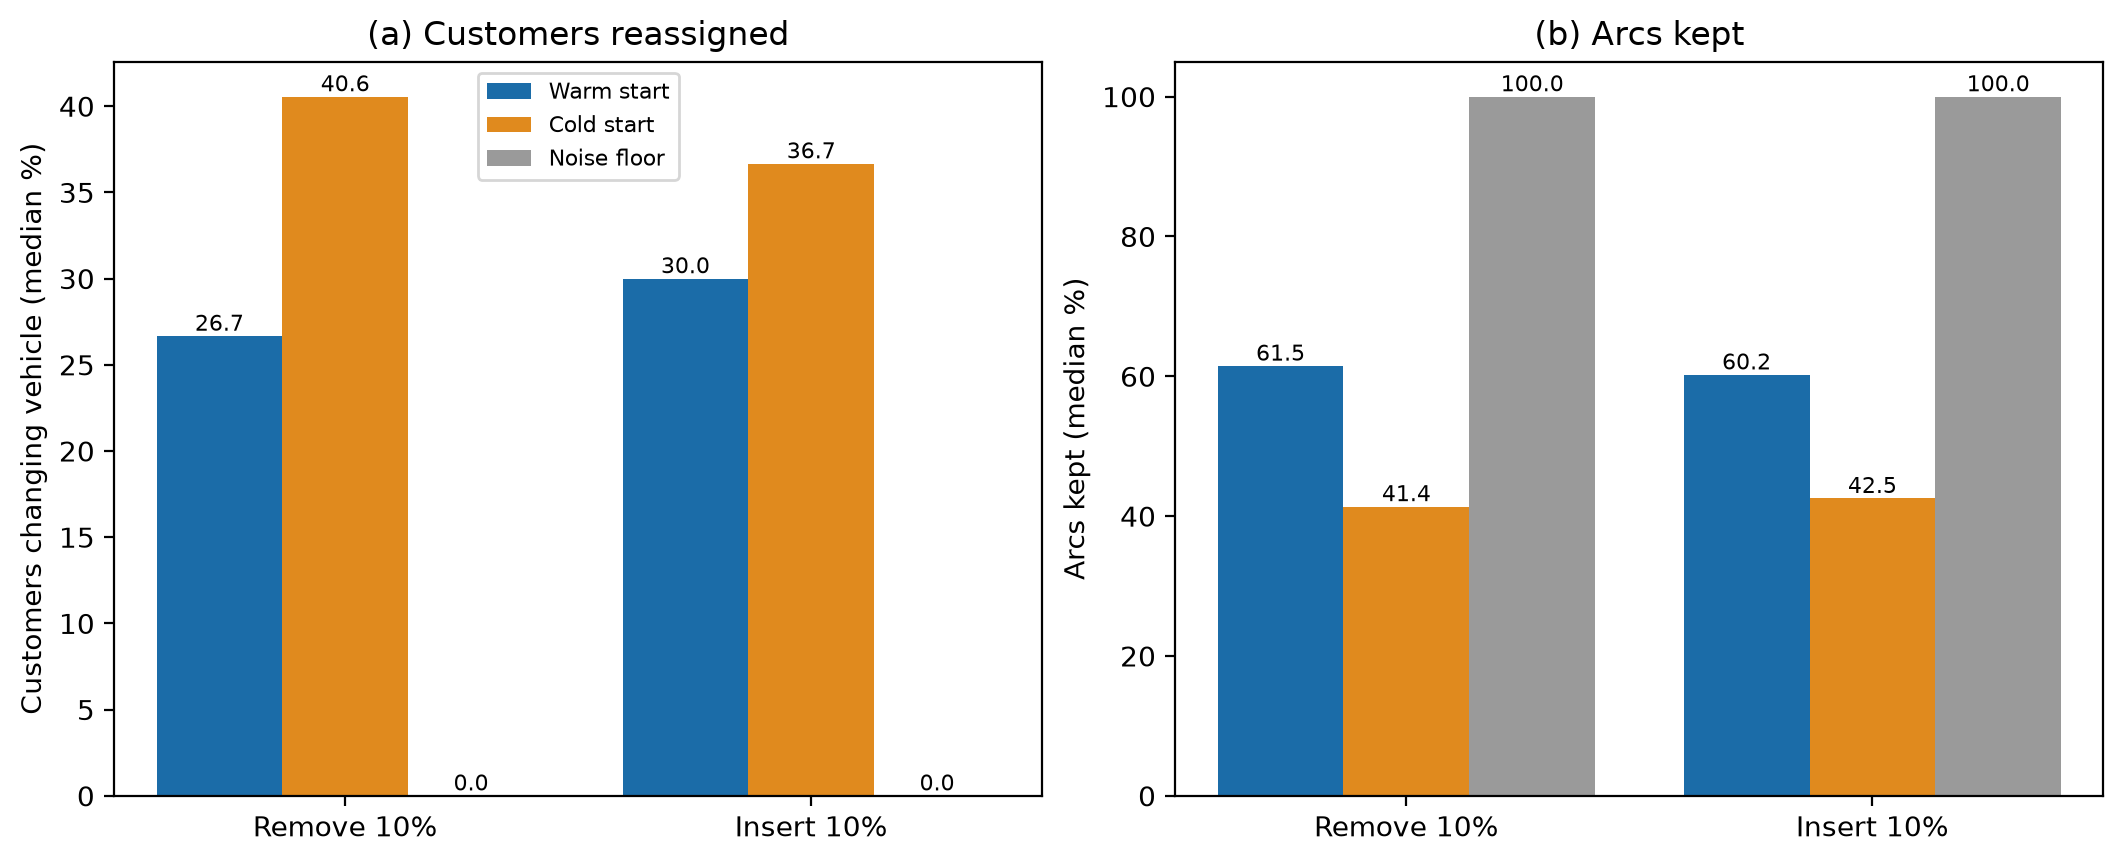

In [9]:
display(eda.localize_columns(phase_c_view.reopt_table_representative(removal, insertion, LANG), LANG))
display(eda.localize_columns(phase_c_view.reopt_noise_table(removal, insertion, LANG), LANG))

viz_robustness.plot_reoptimisation(removal, insertion, LANG)
plt.show()

**Insight.** Starting from the previous plan **preserves more of the plan** and reaches an equal or better distance; the conclusion holds with the representative replicate of each instance (the 14 instances weigh once per variant). In the 10% removal, the warm reoptimisation changes the vehicle of 26.7% of the common customers (median over the 14 instances), against 40.6% cold (40.0% when all the replicates are pooled, the first aggregation); it keeps 64.9% of the pairs and 61.5% of the arcs, against 51.0% and 41.4%; the change in vehicles is −0.57 (warm) and −0.50 (cold) and the distance change is −3.4% and −2.6%. In the 10% insertion, warm changes 30.0% of the customers against 36.7% cold (the same with the replicates pooled), keeps 55.2% of the pairs and 60.2% of the arcs, against 46.9% and 42.5%; vehicles grow by +0.64 and +0.57 and distance by +6.1% and +7.0%. Even warm, an event of 10% of the customers reallocates 27% to 30% of the others: replanning has a relevant operational cost. **The noise floor is not zero in removal:** of the 42 cold-versus-cold comparisons, 4 reassigned customers (R111, 23.3% in 2 comparisons, and RC203, 3.3% in 2 comparisons), although the median is 0.0%; in insertion, 0 of 42 (maximum 0.0%). There is therefore solver variation in 2 of the 14 instances in removal, up to 23.3% in R111, and a warm-versus-cold difference of that size in a single instance is not evidence. **Limitations:** the noise floor was measured on an idle machine and with 3 replicates (3 comparisons per instance), and runs on a busy machine can vary more (notebook 06, section 6 shows this); 14 development instances, with the same customer sample in removal and insertion; the insertion warm start uses a plan built by insertion, not a solver solution; medians over 14 instances hide the variation between instances. **Next decision:** synthesise.

## 7. Synthesis and limitations

**What the results support (descriptively, in layer B):**

- **Robustness (C1):** the optimised OR-Tools plans are not more fragile than the baseline plans **per customer** (6.3% of customers late against 9.3% and 21.1% with travel +0–10%; late return to the depot about 2 to 3 times smaller), but they have **more routes with some lateness** under the service shock (84.2% against 71.1% and 72.5%). The lateness is not negligible: even with travel +0–5%, more than half of the OR-Tools routes have some late customer.
- **Slack explains the fragility:** the correlation between nominal slack and late rate is negative in all cases (−0.37 to −0.78); R1 and RC1 (mean slack of 38 to 41) are late for 13.1% and 11.1% of the customers with travel +0–10%, against 1.0% in C1 (slack of 168).
- **Capacity (C2.1):** with 90% and 80% of Q, 0.21 and 0.57 extra vehicles per instance are needed (3 and 6 of the 14 instances, concentrated in the C families, where capacity already limited the fleet), with +13.9% and +13.6% distance in the larger-fleet instances; with an equal fleet, the distance practically does not change.
- **Limited fleet with priority (C2.2):** with K − 1 and K − 2, the solver leaves about 8 and 25 customers per instance unserved; priority reduces the unserved priority customers from 23 to 0 and from 69 to 3, at the cost of +0.8 and +1.4 unserved common customers per instance. "Unserved" becomes an explicit business decision. The number dropped varies between replicates of the same cell (in RC108 with K − 2 and uniform penalty, 9, 7 and 7 customers), because the penalty encourages service but the heuristic does not guarantee a minimal drop.
- **Reoptimisation (C3):** starting from the previous plan preserves more (26.7% against 40.6% of customers reallocated in removal; 30.0% against 36.7% in insertion; representative replicate of each instance) and reaches an equal or better distance, but an event of 10% of the customers reallocates 27% to 30% of the others; the noise floor has a median of 0% but is not zero in removal (4 of 42 cold-versus-cold comparisons reassigned customers, up to 23.3%, in R111 and RC203).

**What the results do not support:**

- **Flexible windows (C2.3, exploratory):** only 3 of 14 instances were solved (4 infeasible by capacity and 7 with an initial-construction failure within 1.3 s); the block does not support a general conclusion, and fixing it requires a warm start that was not pre-registered (future work).
- Optimality, robustness as an objective or causes: the solver minimises fleet and distance, and robustness and time are by-products; the explanations offered (longer routes, position of the customer in the route) are consistent with the data but were not tested.
- Comparison with SINTEF or with a real operation: layer B has no external reference, and the data are synthetic (coordinates on a plane, no traffic, generated demand and windows).

**Limitations of the phase:** (1) C2.3 failed in 7 of the 10 possible instances because of a limitation of the initial construction, not of time; (2) C1 uses evaluation plans descriptively, with independent shocks per arc, without the spatial and temporal correlation of real traffic; (3) C2 and C3 use only 14 development instances, and the fleet classes have 3 to 8 instances; (4) the robustness and time gains are not a solver objective; (5) the noise floor of C3 was measured on an idle machine with 3 replicates and is not zero in removal.

**Next step:** reoptimisation and delays suggest, as future work, measuring the robustness of plans chosen with a minimum slack per customer and fixing C2.3 with a warm start, which would require a new pre-registered protocol.

## References

- Archetti, C., Speranza, M. G., & Vigo, D. (2014). Vehicle routing problems with profits. In P. Toth & D. Vigo (Eds.), *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.
- Gendreau, M., Laporte, G., & Séguin, R. (1996). Stochastic vehicle routing. *European Journal of Operational Research, 88*(1), 3–12.
- Metropolis, N., & Ulam, S. (1949). The Monte Carlo method. *Journal of the American Statistical Association, 44*(247), 335–341.
- Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- Pillac, V., Gendreau, M., Guéret, C., & Medaglia, A. L. (2013). A review of dynamic vehicle routing problems. *European Journal of Operational Research, 225*(1), 1–11.
- Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101.
- Taillard, É., Badeau, P., Gendreau, M., Guertin, F., & Potvin, J.-Y. (1997). A tabu search heuristic for the vehicle routing problem with soft time windows. *Transportation Science, 31*(2), 170–186.